# Playing card

An adjustable playing card. `@svg.widgets.controls` declares a control per parameter, so
`svgwriter preview` shows a form beside the card, a notebook can call `svg.interact(card)`, and
`svg.sweep` turns the same parameters into an animation.

In [1]:
import functools

from IPython import display as ipy
import svgwriter as svg

from animations import deal
from components import PIP_COLUMNS, corner_index, court, pips

The project's theme applies to every drawing below, as it does when the project builds.

In [2]:
project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)

In [3]:
RANKS = ["A", *PIP_COLUMNS, "J", "Q", "K"]
SUITS = {"♠": "foreground", "♥": "error", "♦": "error", "♣": "foreground"}
"""Each suit's ink, as a palette colour of the theme."""
ASPECT = 1.4      # poker cards are 63 x 88 mm
MARGIN = 24       # felt around the card
INSET = 0.2       # share of the card width kept free for the corner indices
FRAME = 0.85      # the dashed frame, as a share of that inset

The card is a function of its controls. The corner indices, the pips and the court panel are layout
groups from `components/`: they size themselves to their content and to the card, so changing the
width re-lays out every part.

In [4]:
@svg.widgets.controls(
    rank=svg.widgets.Segmented(RANKS, value="Q"),
    suit=svg.widgets.Segmented(list(SUITS), value="♥"),
    hue=svg.widgets.Slider(0, 360, step=1, value=330, format="{:.0f}°"),
    iridescence=svg.widgets.Slider(0, 1, step=0.05, value=0.35),
    glow=svg.widgets.Toggle(True, label="glow"),
    radius=svg.widgets.Slider(0, 30, step=1, value=14, label="corner radius"),
    width=svg.widgets.Slider(160, 320, step=10, value=220, label="card width"),
)
def card(doc: svg.Document, *, rank: str = "Q", suit: str = "♥", hue: float = 330,
         iridescence: float = 0.35, glow: bool = True, radius: float = 14, width: float = 220) -> svg.Document:
    """Draw the card on felt into *doc* and size the page to it."""
    height = width * ASPECT
    theme = doc.theme
    ink = theme.palette[SUITS[suit]]
    accent = svg.Color.from_hsl(hue, 0.65, 0.45)
    doc.rect(0, 0, width + 2 * MARGIN, height + 2 * MARGIN).as_role("felt")

    with doc.group() as face:
        stock = doc.rect(MARGIN, MARGIN, width, height, rx=radius, stroke=accent, stroke_width=2).as_role("surface")
        if glow:
            stock.filter = svg.filters.glow(8, color=accent)
        if iridescence:
            doc.rect(MARGIN, MARGIN, width, height, rx=radius, opacity=iridescence,
                     fill=svg.gradients.iridescent(hue, sweep=240, angle=35))
        inner = width * INSET
        frame = inner * FRAME
        doc.rect(MARGIN + frame, MARGIN + frame, width - 2 * frame, height - 2 * frame,
                 rx=max(radius - frame, 0), fill="none", stroke=accent, stroke_width=1, stroke_dasharray="4 3")

        middle_w, middle_h = width - 2 * inner, height - 2 * inner
        if rank in ("J", "Q", "K"):
            middle = court(rank, suit, ink, accent, width=middle_w, height=middle_h, radius=max(radius - inner, 2))
        else:
            middle = pips(rank, suit, ink, width=middle_w * 0.8, height=middle_h * 0.9, size=width * 0.15)
        holder = svg.HStack(middle, width=middle_w, height=middle_h, align="center", justify="center")
        holder.matrix = svg.Matrix.translate(MARGIN + inner, MARGIN + inner)
        doc += holder

        centre = (MARGIN + width / 2, MARGIN + height / 2)
        for turn in (0, 180):
            index = corner_index(rank, suit, ink)
            index.matrix = svg.Matrix.rotate(turn, *centre) @ svg.Matrix.translate(MARGIN + inner * 0.12, MARGIN + inner * 0.15)
            doc += index
    face.animate.apply(deal)
    return doc.fit()

The sweep steps through every suit while the hue turns a full circle and the iridescence swells; the
project builds it as a GIF and as an animated SVG next to the card.

In [5]:
sweep = svg.sweep(card, suit=list(SUITS), hue=(0, 360), iridescence=(0.1, 0.8), dur=4, fps=12,
                  ease="ease-in-out", name="sweep")
outputs = [card, sweep]

Every control of `card` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [6]:
def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.interact(in_project(card))

The same function for other control values.

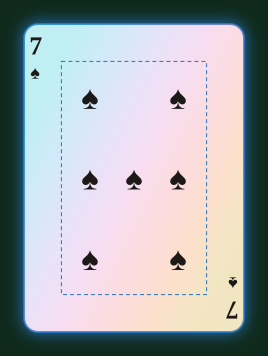

In [7]:
show(card, **{'rank': '7', 'suit': '♠', 'hue': 210})

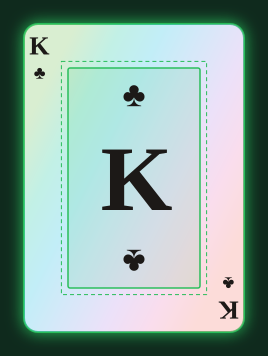

In [8]:
show(card, **{'rank': 'K', 'suit': '♣', 'hue': 140})

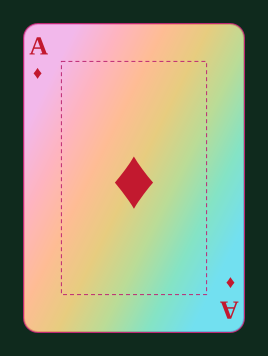

In [9]:
show(card, **{'rank': 'A', 'suit': '♦', 'iridescence': 0.8, 'glow': False})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

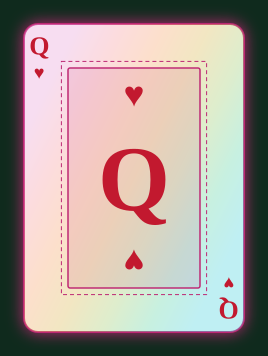

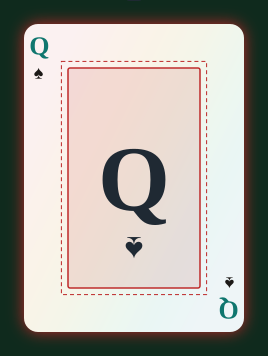

In [10]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))